['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


/tmp/ipykernel_97334/2166859604.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()
/tmp/ipykernel_97334/2166859604.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend()


Text(0.05, 1.02, 'c')

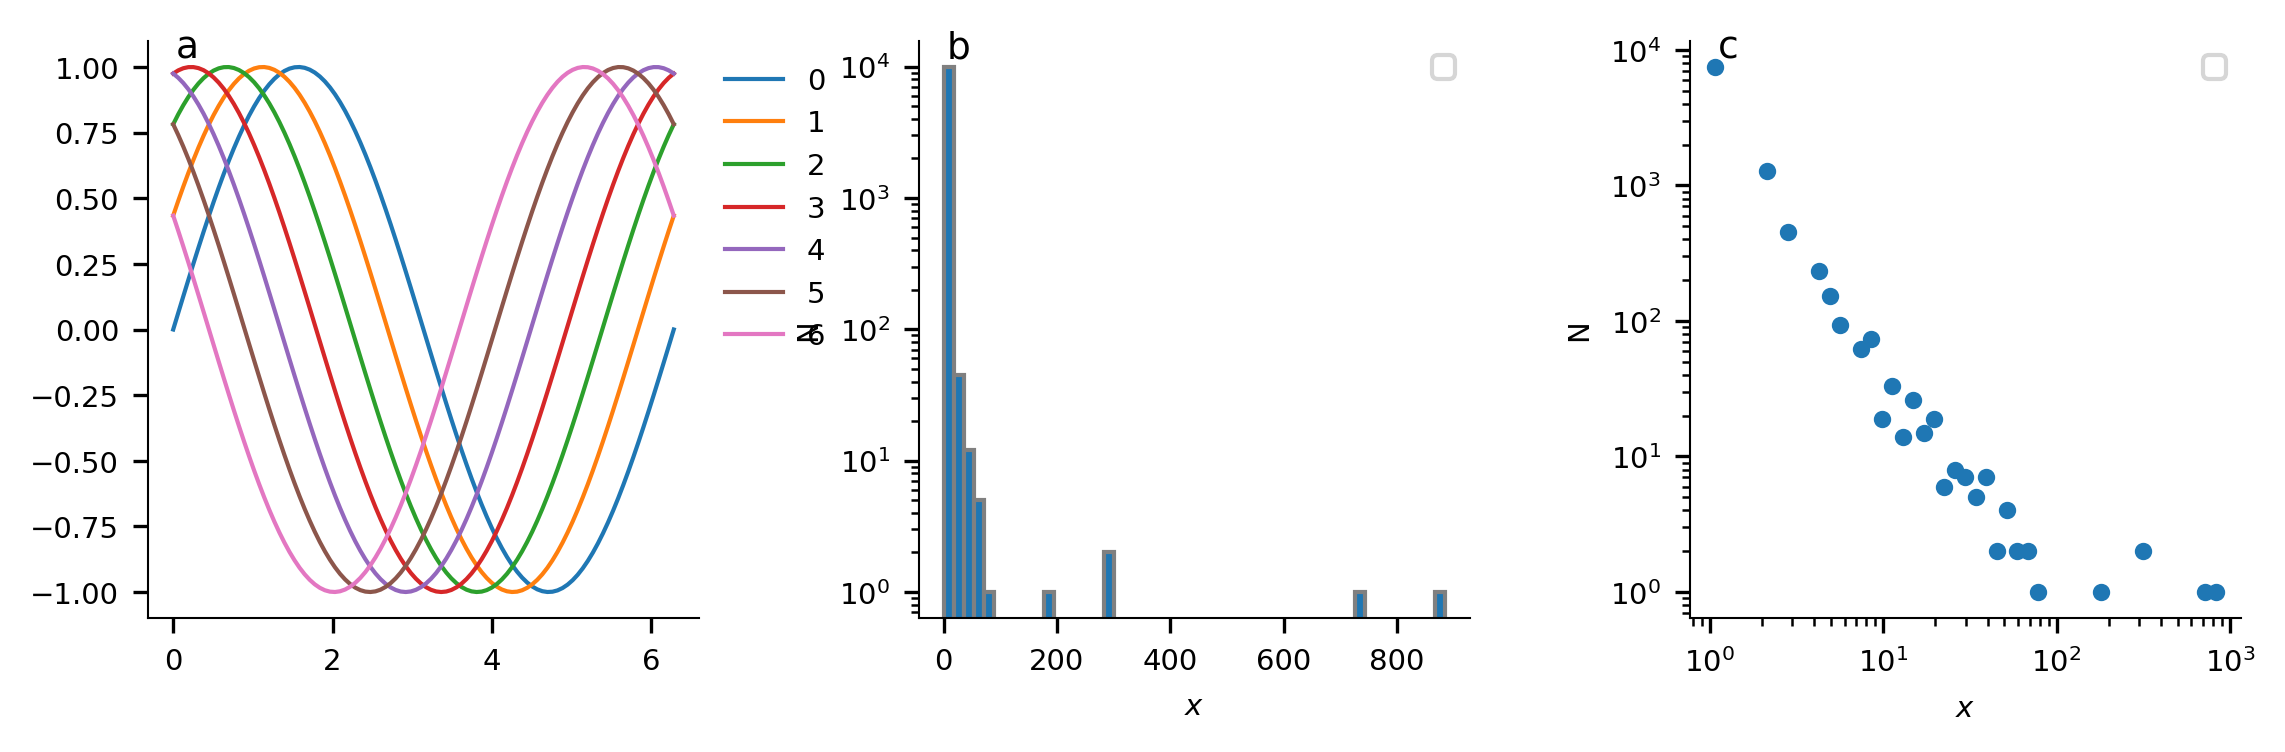

In [1]:
import polars as pl
import matplotlib.pyplot as plt
from constant import openalex_path
import numpy as np

import scienceplots
plt.rcParams['figure.dpi'] = 300
plt.style.use(['nature']) # start with ['science'] then ['nature']. use 'notebook', 'no-latex', 'cjk-jp-font' if needed.
plt.rcParams.update({'font.size': 12})
# https://github.com/garrettj403/SciencePlots
print(plt.rcParams['axes.prop_cycle'].by_key()['color'])


fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize=(9,2.5))
fig.subplots_adjust(hspace=0.1, wspace=0.4)

n = 7
x = np.linspace(0, 2*np.pi, 100)
for i in range(n):
    ax1.plot(x, np.sin(x+np.pi/n*i), label=i)
ax1.spines[['right', 'top']].set_visible(False)
ax1.tick_params(which='both', top=False, right=False)
ax1.legend(loc='upper left', bbox_to_anchor=(1,1),frameon=False)
ax1.text(0.05, 1.02, 'a', va='top', transform=ax1.transAxes, fontsize=9)


np.random.seed(0)
a = 2.5  # べき分布の指数（べき指数）
size = 10000  # データのサイズ
data = np.random.zipf(a, size)

ax2.hist(data, bins=50, log=True, edgecolor='gray')
ax2.set_xlabel('$x$')
ax2.set_ylabel('N')
ax2.spines[['right', 'top']].set_visible(False)
ax2.tick_params(which='both', top=False, right=False)
ax2.legend()
ax2.text(0.05, 1.02, 'b', va='top', transform=ax2.transAxes, fontsize=9)

bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 50)
hist, bin_edges = np.histogram(data, bins=bins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
ax3.scatter(bin_centers, hist, s=10)
ax3.set_xscale('log')  # x軸を対数スケールに設定
ax3.set_yscale('log')  # y軸を対数スケールに設定
ax3.set_xlabel('$x$')
ax3.set_ylabel('N')
ax3.spines[['right', 'top']].set_visible(False)
ax3.tick_params(which='both', top=False, right=False)
ax3.legend()
ax3.text(0.05, 1.02, 'c', va='top', transform=ax3.transAxes, fontsize=9)

In [2]:
# CNS_papers_details_df =  pl.read_parquet("./data/CNS_paper_details.parquet")
CNS_papers_details_df =  pl.read_parquet("./data/CNS_papers_inferred_subjects_Life.parquet")
CNS_citing_preprints_df = pl.read_parquet("./data/citing_preprints_full_enhanced.parquet").filter(pl.col("work_id").is_in(CNS_papers_details_df["work_id"].to_list()))
journal_detail = pl.read_parquet("./data/CNS_journal_inception.parquet")
preprint = pl.read_parquet("./data/preprints_opal_0129_curation_imputed.parquet").drop_nulls("work_id")

In [3]:
CNS_papers_details_df.select("publication_year").max()

publication_year
i64
2023


In [5]:
threshold = 5

In [6]:
source_lf = pl.scan_parquet(f"{openalex_path}/works/primary_location_id/*")

sources_journal = (
    pl.scan_parquet("./data/CNS_citing_journals.parquet").select("referenced_works")
    .join(source_lf, left_on="referenced_works", right_on="work_id", how="left")
    .group_by("primary_location_id").len()
    .filter(pl.col("len") >= threshold)
    .drop("len")
)

all_works_count = (
    pl.scan_parquet(f"{openalex_path}/works/publication_year/*")
    .join(source_lf, on="work_id", how="left")
    .join(sources_journal, left_on="primary_location_id", right_on="primary_location_id", how="semi")
    .filter(pl.col("publication_year").is_between(2000, 2024))
    .group_by("publication_year")
    .agg(
        pl.count("work_id").alias("total_works")
    )
    .collect(engine="streaming")
)
all_works_count.sort("publication_year")

/tmp/ipykernel_97334/196857082.py:20: UserWarning: '(default_)region' not set; polars will try to get it from bucket

Set the region manually to silence this warning.
  .collect(engine="streaming")


publication_year,total_works
i64,u32
2000,1537247
2001,1556598
2002,1643611
2003,1789889
2004,1895811
…,…
2020,5062335
2021,4836914
2022,4993575


In [7]:
sources_preprint = (
    CNS_citing_preprints_df
    .select(pl.col("primary_category").alias("primary_location_id"))
    .group_by("primary_location_id").len()
    .filter(pl.col("len") >= threshold)
    .drop("len")
)

# ratio of preprint counts by year bins
preprint_count = (
    preprint
    .join(sources_preprint, left_on="primary_category", right_on="primary_location_id", how="semi")
    .group_by("publication_year_preprint")
    .agg(
        pl.count("work_id").alias("num_preprints"),
        pl.col("curated_doi").is_null().sum().alias("num_noncurated_preprints"),
        pl.col("curated_doi").is_not_null().sum().alias("num_curated_preprints")
    )
    .filter(pl.col("publication_year_preprint").is_between(2000, 2024))
    .sort("publication_year_preprint")
)
preprint_count

publication_year_preprint,num_preprints,num_noncurated_preprints,num_curated_preprints
i32,u32,u32,u32
2000,10871,3022,7849
2001,12201,2835,9366
2002,13082,2944,10138
2003,14736,3272,11464
2004,15824,3168,12656
…,…,…,…
2020,137580,54107,83473
2021,139052,57339,81713
2022,140786,62693,78093


In [8]:
all_works_count.sort("publication_year")

publication_year,total_works
i64,u32
2000,1537247
2001,1556598
2002,1643611
2003,1789889
2004,1895811
…,…
2020,5062335
2021,4836914
2022,4993575


In [9]:
noncurated = pl.when(pl.col("curated_doi").is_null()).then(pl.col("work_id"))
curated = pl.when(pl.col("curated_doi").is_not_null()).then(pl.col("work_id"))

pub_year_preprint_citation_count = (
    CNS_citing_preprints_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by("publication_year")
    .agg(
        pl.n_unique("work_id").alias("num_citing_preprints"),
        pl.count("work_id").alias("num_citation_preprints"),
        noncurated.n_unique().alias("num_citing_noncurated_preprints"),
        noncurated.count().alias("num_citation_noncurated_preprints"),
        curated.n_unique().alias("num_citing_curated_preprints"),
        curated.count().alias("num_citation_curated_preprints"),
    )
    .sort("publication_year")
)

CNS_paper_yearly_count = (
    CNS_papers_details_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by("publication_year")
    .agg(
        pl.count().alias("total_article"),
        pl.col("ref_count").sum().alias("total_ref_count")
    )
)

article_count = (
    preprint_count
    .join(all_works_count, left_on="publication_year_preprint", right_on="publication_year", how="left")
    .with_columns(
        (pl.col("num_preprints") / pl.col("total_works")).alias("preprint_ratio"),
        (pl.col("num_noncurated_preprints") / pl.col("total_works")).alias("preprint_ratio_noncurated"),
        (pl.col("num_curated_preprints") / pl.col("total_works")).alias("preprint_ratio_curated")
    )
)
article_count

/tmp/ipykernel_97334/3296052499.py:26: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("total_article"),


publication_year_preprint,num_preprints,num_noncurated_preprints,num_curated_preprints,total_works,preprint_ratio,preprint_ratio_noncurated,preprint_ratio_curated
i32,u32,u32,u32,u32,f64,f64,f64
2000,10871,3022,7849,1537247,0.007072,0.001966,0.005106
2001,12201,2835,9366,1556598,0.007838,0.001821,0.006017
2002,13082,2944,10138,1643611,0.007959,0.001791,0.006168
2003,14736,3272,11464,1789889,0.008233,0.001828,0.006405
2004,15824,3168,12656,1895811,0.008347,0.001671,0.006676
…,…,…,…,…,…,…,…
2020,137580,54107,83473,5062335,0.027177,0.010688,0.016489
2021,139052,57339,81713,4836914,0.028748,0.011854,0.016894
2022,140786,62693,78093,4993575,0.028193,0.012555,0.015639


In [10]:
citing_preprint_probability = (
    pub_year_preprint_citation_count
    .join(preprint_count, left_on="publication_year", right_on="publication_year_preprint", how="left")
    .join(CNS_paper_yearly_count, on="publication_year", how="inner")
    .join(all_works_count, on="publication_year", how="left")
    .filter(pl.col("publication_year").is_between(2000,2024))
    .with_columns(
        (pl.col("num_citing_noncurated_preprints") / pl.col("total_article")).alias("citing_noncurated_preprint_probability"),
        (pl.col("num_citing_curated_preprints") / pl.col("total_article")).alias("citing_curated_preprint_probability"),
        (pl.col("num_citation_noncurated_preprints") / pl.col("total_ref_count")).alias("citation_noncurated_preprint_probability"),
        (pl.col("num_citation_curated_preprints") / pl.col("total_ref_count")).alias("citation_curated_preprint_probability"),
        (pl.col("num_noncurated_preprints") / pl.col("total_works")).alias("noncurated_preprint_ratio"),
        (pl.col("num_curated_preprints") / pl.col("total_works")).alias("curated_preprint_ratio")
    )
    .sort("publication_year")
)

In [11]:
article_count.filter(pl.col("publication_year_preprint").is_between(2008, 2011))

publication_year_preprint,num_preprints,num_noncurated_preprints,num_curated_preprints,total_works,preprint_ratio,preprint_ratio_noncurated,preprint_ratio_curated
i32,u32,u32,u32,u32,f64,f64,f64
2008,21401,4289,17112,2393537,0.008941,0.001792,0.007149
2009,12989,3859,9130,2567909,0.005058,0.001503,0.003555
2010,15246,4803,10443,2679770,0.005689,0.001792,0.003897
2011,17138,5222,11916,3078774,0.005567,0.001696,0.00387


In [12]:
citing_preprint_probability.select(
    "publication_year", 
    "total_ref_count", 
    "num_citation_noncurated_preprints", 
    "citation_noncurated_preprint_probability"
    )

publication_year,total_ref_count,num_citation_noncurated_preprints,citation_noncurated_preprint_probability
i64,u32,u32,f64
2003,76473,1,0.000013
2004,125044,0,0.0
2005,142126,1,0.000007
2006,138179,4,0.000029
2007,134788,3,0.000022
…,…,…,…
2019,211019,465,0.002204
2020,234788,1025,0.004366
2021,223413,1311,0.005868


In [13]:
1020 / 218897

0.004659725807114762

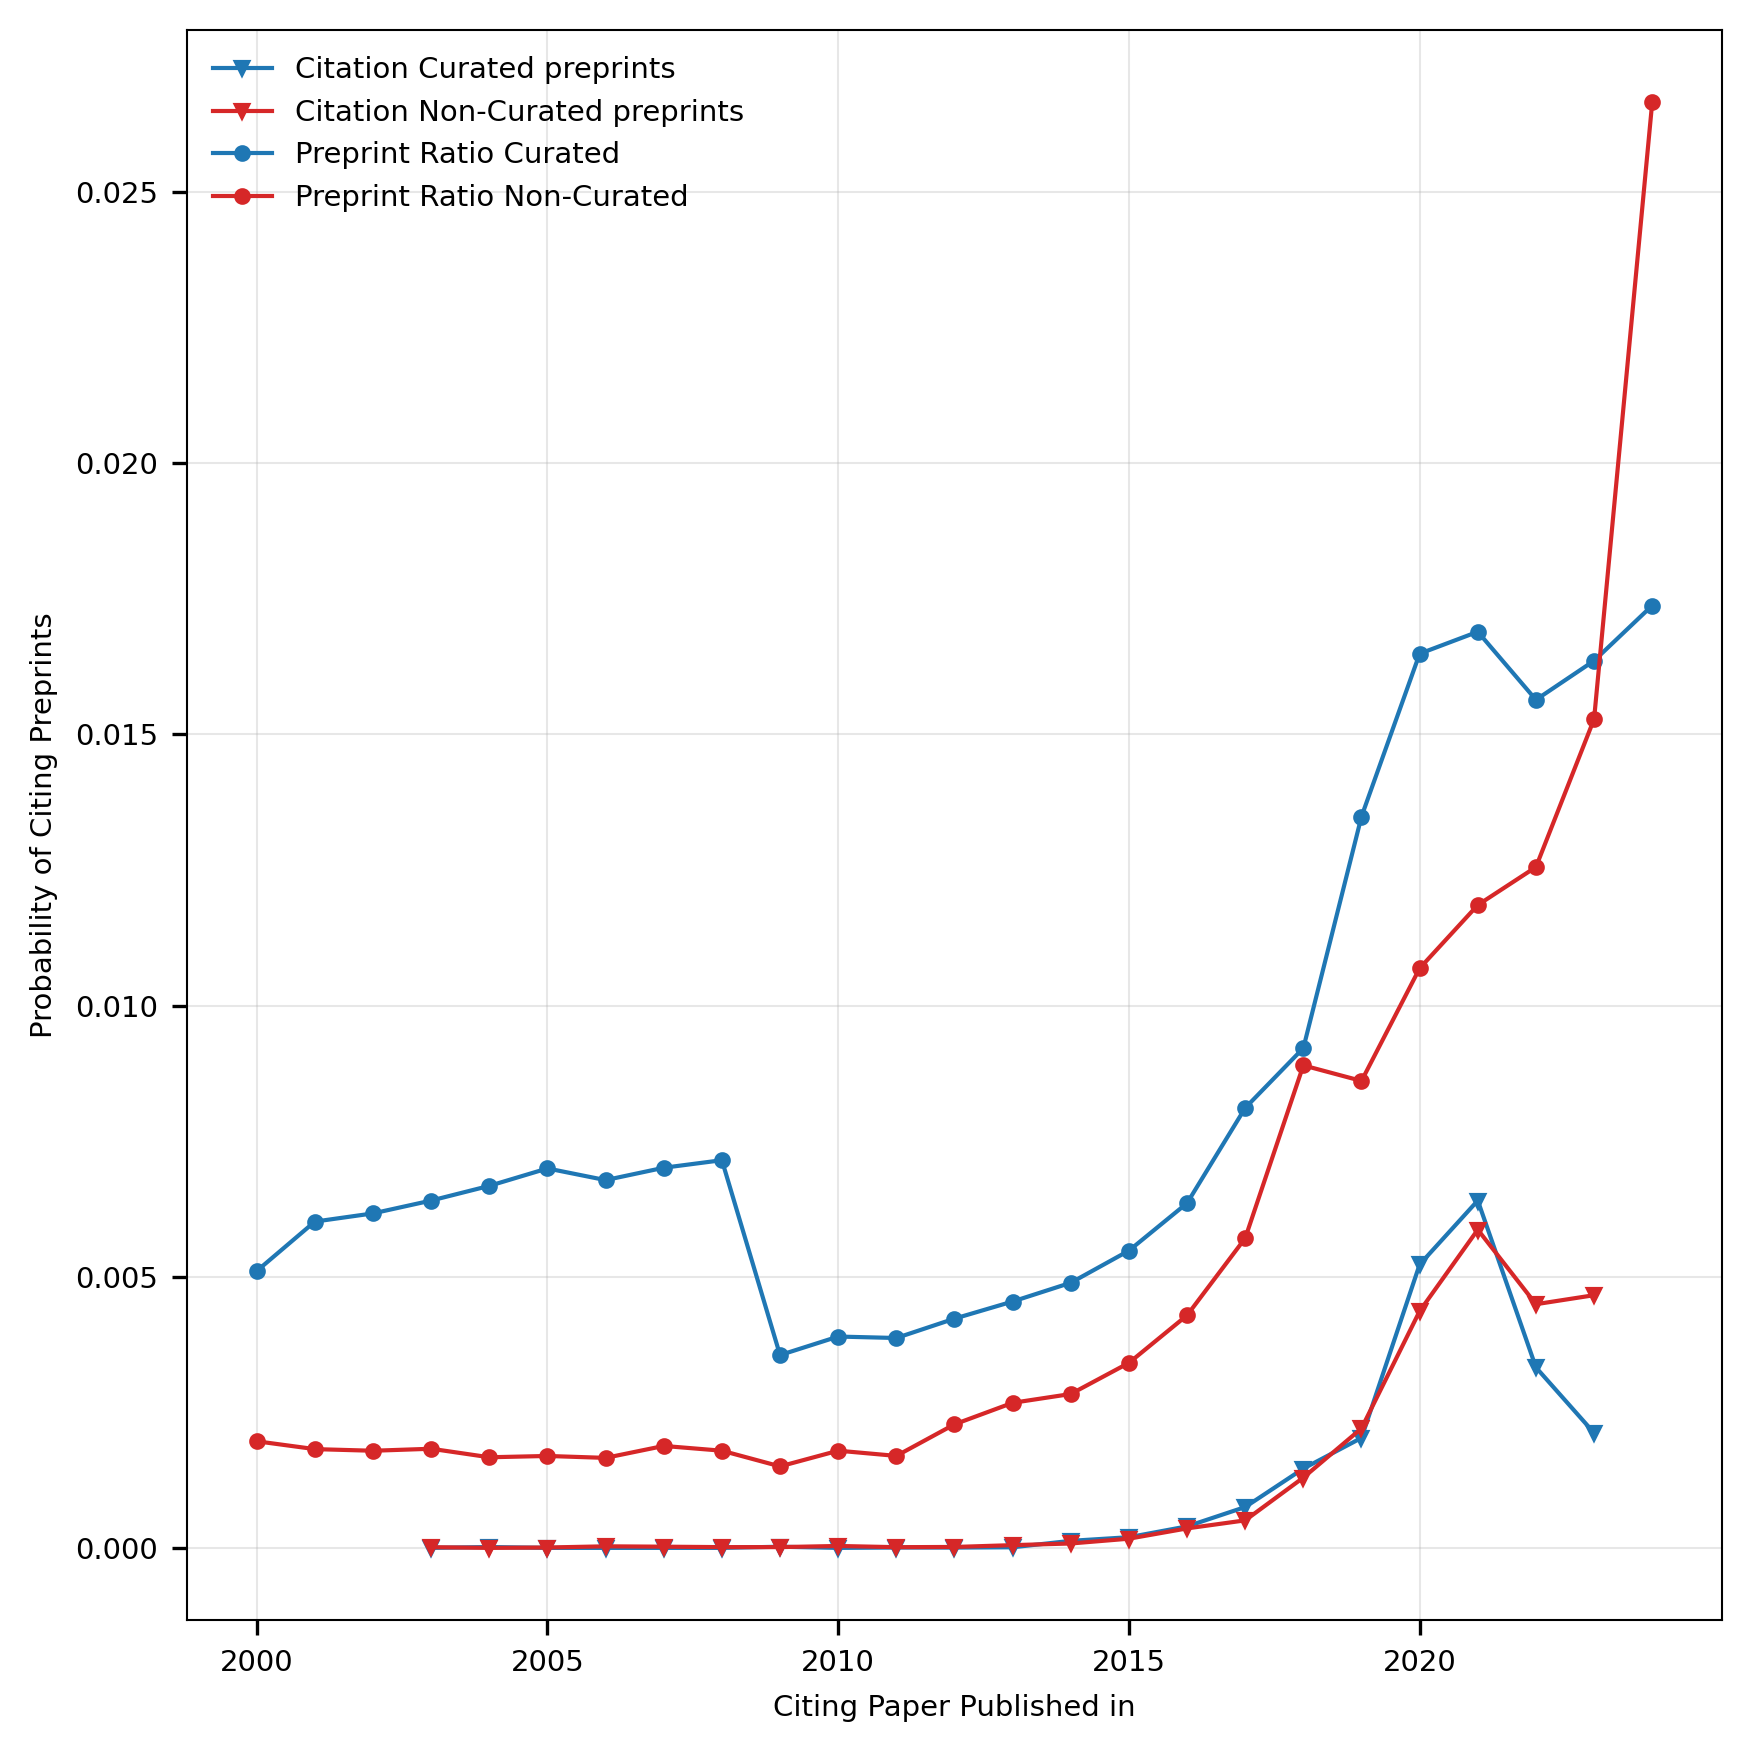

In [14]:
pdf = citing_preprint_probability

plt.figure(figsize=(6, 6))
plt.plot(pdf["publication_year"].to_list(), pdf["citation_curated_preprint_probability"].to_list(), marker="v", linestyle="-", color="tab:blue", label="Citation Curated preprints")
plt.plot(pdf["publication_year"].to_list(), pdf["citation_noncurated_preprint_probability"].to_list(), marker="v", linestyle="-", color="tab:red", label="Citation Non-Curated preprints")
plt.plot(article_count["publication_year_preprint"].to_list(), article_count["preprint_ratio_curated"].to_list(), marker="o", linestyle="-", color="tab:blue", label="Preprint Ratio Curated")
plt.plot(article_count["publication_year_preprint"].to_list(), article_count["preprint_ratio_noncurated"].to_list(), marker="o", linestyle="-", color="tab:red", label="Preprint Ratio Non-Curated")
plt.xticks(range(2000, 2025, 5))

plt.xlabel("Citing Paper Published in")
plt.ylabel("Probability of Citing Preprints")
# plt.title("Probability of Citing Preprints by Publication Year (CNS journals, inception Before 2000)")
plt.grid(alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()


/tmp/ipykernel_97334/3930727156.py:4: RuntimeWarning: divide by zero encountered in log10
  plt.plot(pdf["publication_year"].to_list(), np.log10((pdf["citation_curated_preprint_probability"] / pdf["curated_preprint_ratio"]).to_list()), marker="o", markersize=3, linestyle="-", color="tab:blue", label="Curated preprints")
/tmp/ipykernel_97334/3930727156.py:5: RuntimeWarning: divide by zero encountered in log10
  plt.plot(pdf["publication_year"].to_list(), np.log10((pdf["citation_noncurated_preprint_probability"] / pdf["noncurated_preprint_ratio"]).to_list()), marker="v", markersize=3, linestyle="-", color="tab:red", label="Non-Curated preprints")


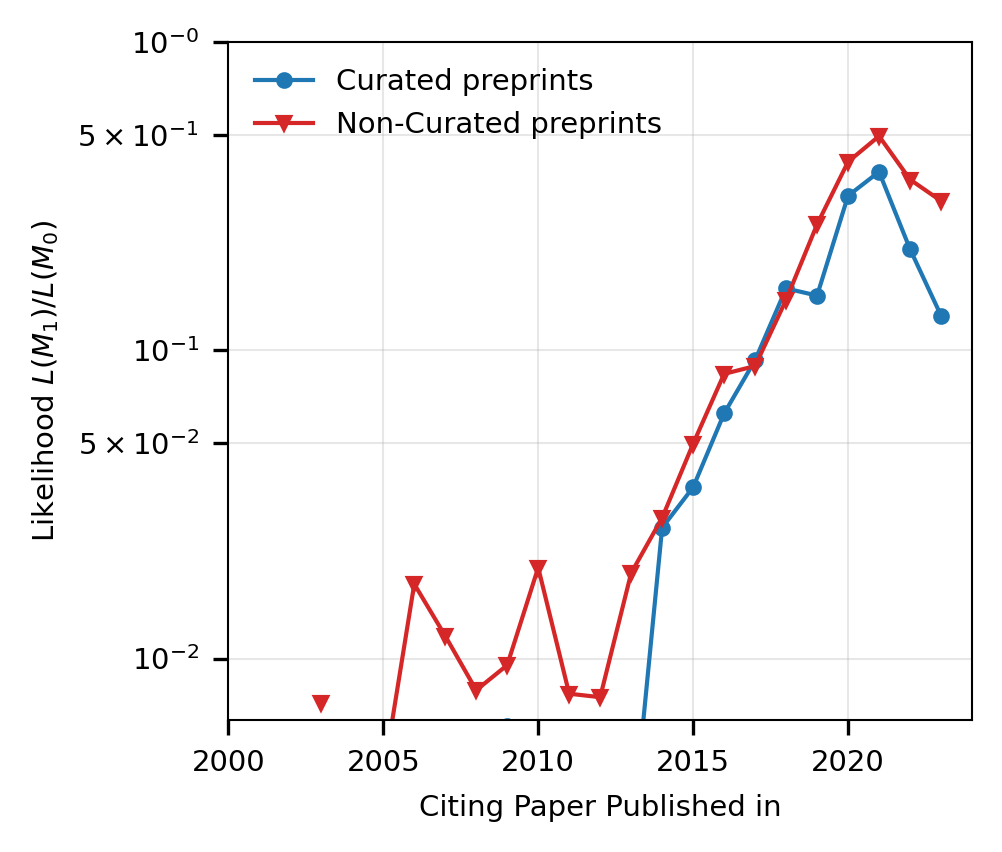

In [38]:
pdf = citing_preprint_probability

plt.figure(figsize=(3.5, 3))
plt.plot(pdf["publication_year"].to_list(), np.log10((pdf["citation_curated_preprint_probability"] / pdf["curated_preprint_ratio"]).to_list()), marker="o", markersize=3, linestyle="-", color="tab:blue", label="Curated preprints")
plt.plot(pdf["publication_year"].to_list(), np.log10((pdf["citation_noncurated_preprint_probability"] / pdf["noncurated_preprint_ratio"]).to_list()), marker="v", markersize=3, linestyle="-", color="tab:red", label="Non-Curated preprints")
plt.xticks(range(2000, 2025, 5))

plt.xlabel("Citing Paper Published in")
plt.ylabel("Likelihood $L(M_1) / L(M_0)$")

import numpy as np

log10_5 = np.log10(5)

ticks = []
labels = []

for k in range(4, -1, -1):  # 例: 10^-4 ～ 10^0
    ticks.append(-k)
    labels.append(rf"$10^{{-{k}}}$")
    
    if k > 0:  # 5×10^0 は不要なら省く
        ticks.append(log10_5 - k)
        labels.append(rf"$5\times10^{{-{k}}}$")

plt.yticks(ticks, labels)

plt.grid(alpha=0.3)
plt.xlim(2000,2024)
plt.ylim(-2.2,0)
# plt.ylim(-3,0)
plt.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("./figures/citing_preprint_probability.pdf")

In [33]:
citing_preprint_probability.filter(pl.col("publication_year").is_between(2008, 2013)).select("publication_year", "num_citing_curated_preprints")

publication_year,num_citing_curated_preprints
i64,u32
2008,1
2009,3
2010,1
2011,2
2012,2
2013,3
